In [ ]:
import pandas as pd

df = pd.read_csv("../data/SeoulBikeData.csv", encoding="latin1")
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13  Functioning Day            8760 non-null   str    
dtypes: 

In [4]:
df.describe()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


In [8]:
# SELECT
#     [Functioning Day],
#     COUNT(*) AS [count],
#     AVG([Rented Bike Count]) AS [mean],
#     MIN([Rented Bike Count]) AS [min],
#     MAX([Rented Bike Count]) AS [max]
# FROM SeoulBikeData
# GROUP BY [Functioning Day];

df.groupby("Functioning Day")["Rented Bike Count"].agg(
    ["count", "mean", "min", "max"]
)

,count,mean,min,max
Functioning Day,,,,
No,295,0.000000,0,0
Yes,8465,729.156999,2,3556


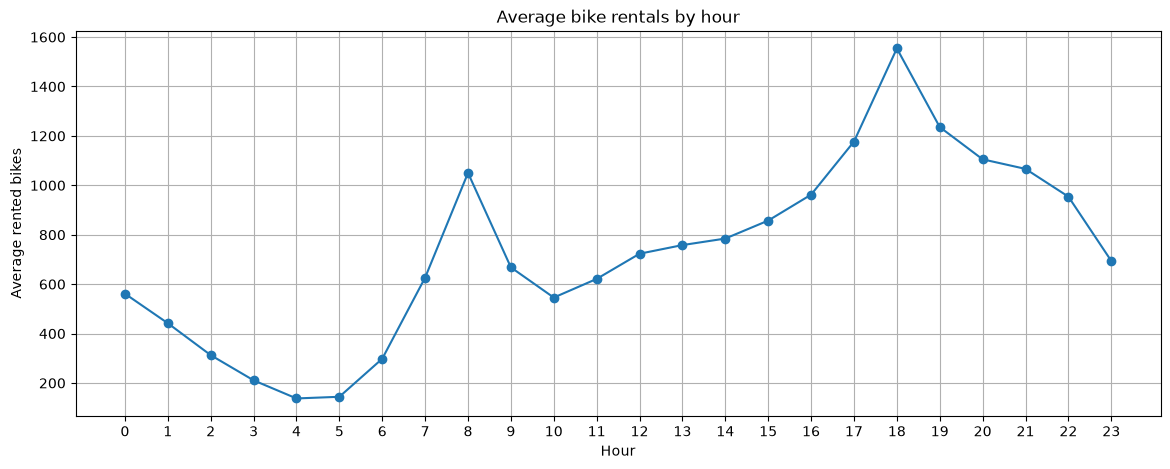

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

ax = df[df["Functioning Day"] == "Yes"].groupby("Hour")["Rented Bike Count"].mean().plot(
    kind="line",
    marker="o",
    title="Average bike rentals by hour",
    xlabel="Hour",
    ylabel="Average rented bikes",
    grid=True
)

ax.set_xticks(range(24))

plt.show()

## Initial Data Analysis (EDA)

We started by exploring the Seoul Bike Sharing dataset to understand what data we have and what might affect bike rentals.

### Dataset overview
- 8,760 rows (hourly data for one year).
- 14 columns.
- No missing values.
- Our target is **Rented Bike Count**.

### What we found

**Bike rentals:**
- Average: about 705 bikes per hour, Median: about 505 bikes, Minimum: 0, Maximum: 3,556.

**Functioning days:**
- There are 295 hours when the rental service was not operating (no bikes were rented).
- When the service was operating, at least 2 bikes were rented per hour.

**Time of day:**
- The lowest demand is around 4:00–5:00.
- There is a morning peak around 8:00.
- The highest peak is around 18:00.
- This might be because people use bikes to travel to and from work.

### Initial conclusions

- **Hour** seems to be an important feature for predicting bike rentals.
- The relationship between time and rental demand is not linear.
- We should also investigate how temperature, weather and seasons affect demand.

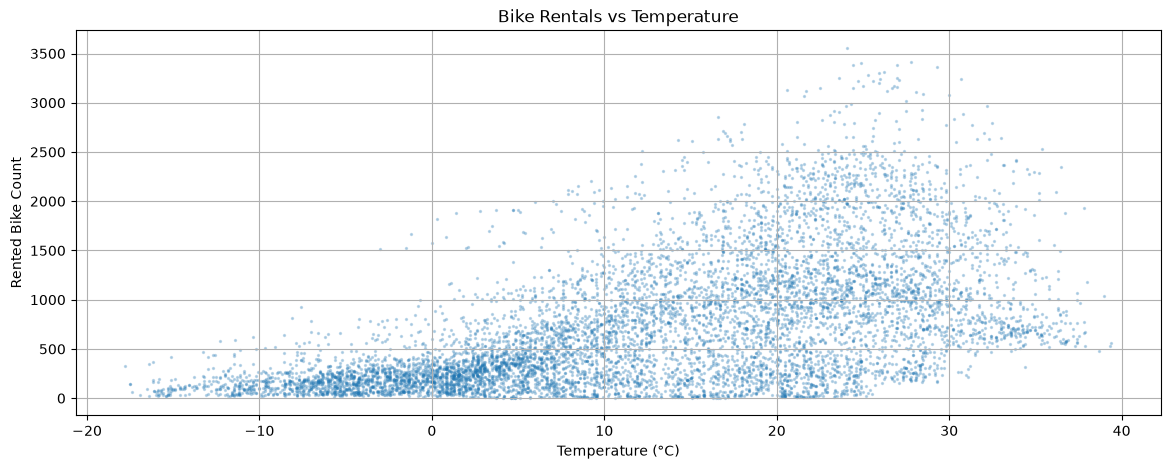

In [25]:
# Bike Rentals vs Temperature

working_days = df[df["Functioning Day"] == "Yes"]

plt.figure(figsize=(14, 5))

plt.scatter(
    working_days["Temperature(°C)"],
    working_days["Rented Bike Count"],
    alpha=0.25,
    s=2
)

plt.title("Bike Rentals vs Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Rented Bike Count")
plt.grid(True)
plt.show()

Temperature seems to affect **the maximum number of bike rentals** rather than the actual demand.  
Low rental counts happen at almost any temperature, but high rental counts are mostly observed in warmer weather.  
The upper limit increases up to around 25°C and then appears to decrease.  
Temperature also depends on the time of day, so the relationship between temperature and bike rentals might be partly explained by the hour.

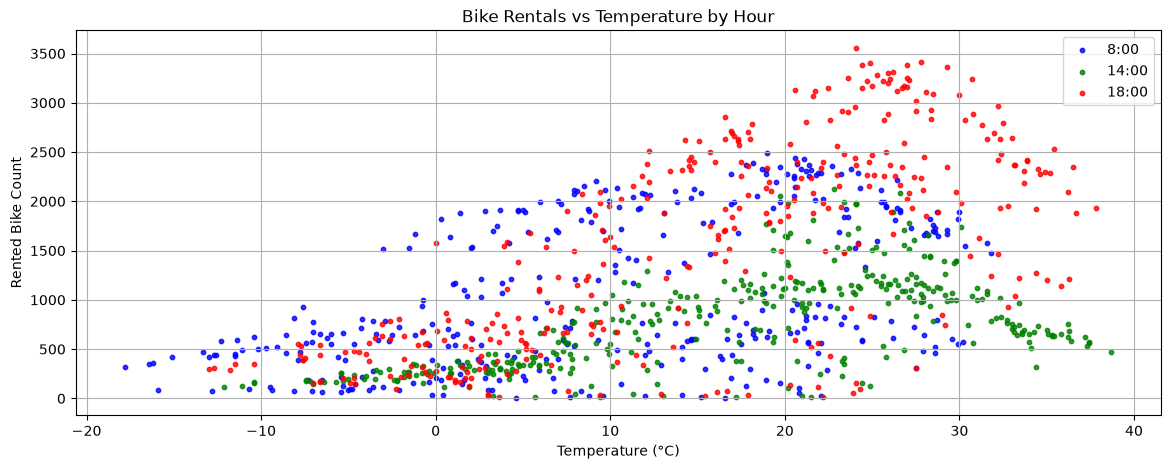

In [ ]:
# Bike Rentals vs Temperature by Hour

plt.figure(figsize=(14, 5))

colors = {
    8: "blue",
    14: "green",
    18: "red"
}

for hour in [8, 14, 18]:
    data = working_days[working_days["Hour"] == hour]

    plt.scatter(
        data["Temperature(°C)"],
        data["Rented Bike Count"],
        color=colors[hour],
        alpha=0.8,
        s=10,
        label=f"{hour}:00"
    )

plt.title("Bike Rentals vs Temperature by Hour")
plt.xlabel("Temperature (°C)")
plt.ylabel("Rented Bike Count")
plt.legend()
plt.grid(True)
plt.show()

The graph shows that the relationship between temperature and bike rentals follows roughly the same pattern at all three selected hours.

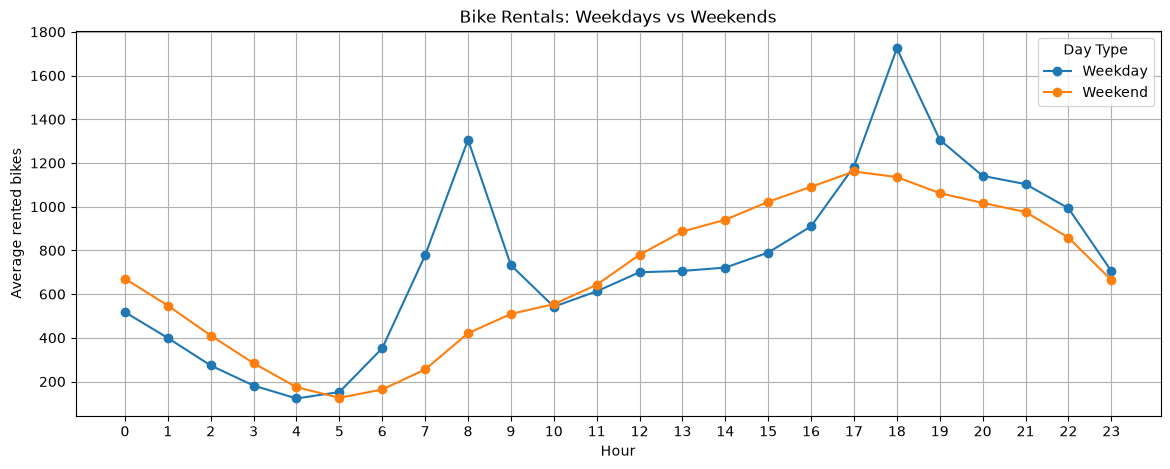

In [36]:
# Weekdays vs Weekends

df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")

working_days = df[df["Functioning Day"] == "Yes"].copy()

working_days["Day Type"] = (working_days["Date"].dt.day_of_week >= 5).map({
    False: "Weekday",
    True: "Weekend"
})

ax = working_days.groupby(["Hour", "Day Type"])["Rented Bike Count"].mean().unstack().plot(
    figsize=(14, 5),
    marker="o",
    title="Bike Rentals: Weekdays vs Weekends",
    xlabel="Hour",
    ylabel="Average rented bikes",
    grid=True
)

ax.set_xticks(range(24))
plt.show()

## Weekdays vs Weekends

The graph shows a clear difference between weekdays and weekends. On weekdays, there are two peaks at 8:00 and 18:00, probably(?) because people travel to and from work. On weekends, there are no sharp peaks, and bike rentals increase gradually during the day.

Apart from these peaks, the graphs for weekdays and weekends follow roughly the same pattern.

### Total observations

Rain
No Rain    7949
Rain        516
Name: count, dtype: int64

### Observations by hour

Rain,No Rain,Rain
Hour,,
0,328,24
1,335,17
2,331,21
3,313,39
4,333,19
5,331,21
6,315,37
7,334,19
8,333,20


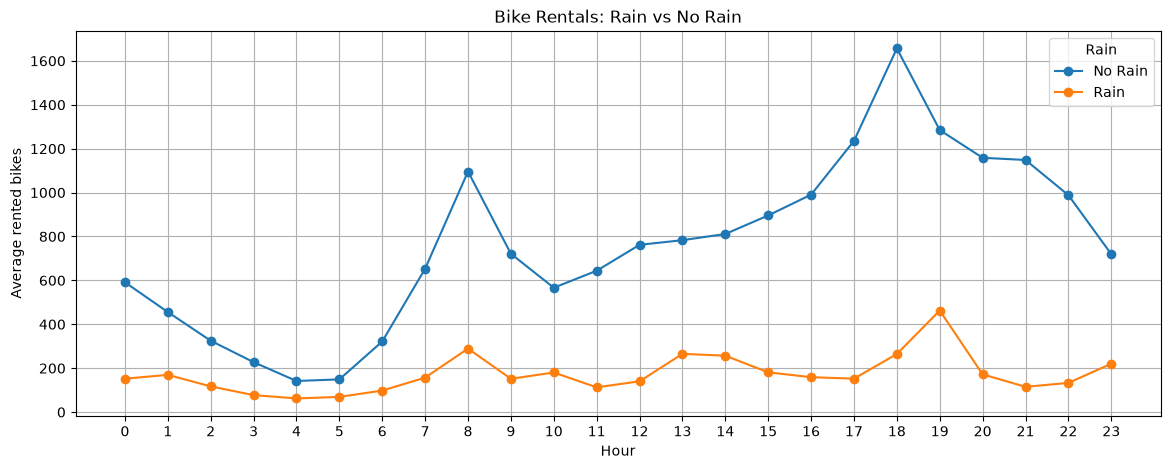

In [ ]:
# Rain vs No Rain

from IPython.display import display, Markdown

working_days["Rain"] = working_days["Rainfall(mm)"].apply(
    lambda rain: "Rain" if rain > 0 else "No Rain"
)

display(Markdown("### Total observations"))
display(working_days["Rain"].value_counts())

display(Markdown("### Observations by hour"))
display(working_days.groupby(["Hour", "Rain"]).size().unstack())

ax = working_days.groupby(["Hour", "Rain"])["Rented Bike Count"].mean().unstack().plot(
    figsize=(14, 5),
    marker="o",
    title="Bike Rentals: Rain vs No Rain",
    xlabel="Hour",
    ylabel="Average rented bikes",
    grid=True
)
ax.set_xticks(range(24))
plt.show()

## Rain vs No Rain

The graph shows that rain has a strong effect on bike rentals. The number of rentals is much lower when it rains, but the overall pattern during the day is quite similar.